# Graphing word frequencies accross a workset using the Extracted Features API



First, we'll install some Python libraries we'll need to use to create our visualization.

In [ ]:
!pip install matplotlib
!pip install requests
!pip install plotly
!pip install dash
!pip install datatime
%matplotlib inline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 66.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.7/101.7 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.0/228.0 kB 14.8 MB/s eta 0:00:00
  Attempting uninstall: Werkzeug
    Found existing installation: Werkzeug 3.1.3
    Uninstalling Werkzeug-3.1.3:
      Successfully uninstalled Werkzeug-3.1.3
  Attempting uninstall: Flask
    Found existing installation: Flask 3.1.0
    Uninstalling Flask-3.1.0:
      Successfully uninstalled Flask-3.1.0
ERROR: Could not find a version that satisfies the requirement datatime (from versions: none)
ERROR: No matching distribution found for datatime


### Bookworm

Many humanities scholars may be familiar with [Bookworm+HTRC](https://bookworm.htrc.illinois.edu/develop/) or the [Google N-gram viewer](https://books.google.com/ngrams/). Both tools allow users to search for specific tokens (words) across a large text dataset and then graphs the results (words per million) in the form of a line graph. While these are great tools for visualizing the use of words on a large scale, some users may be interested in doing a similar analysis, using a select corpus.

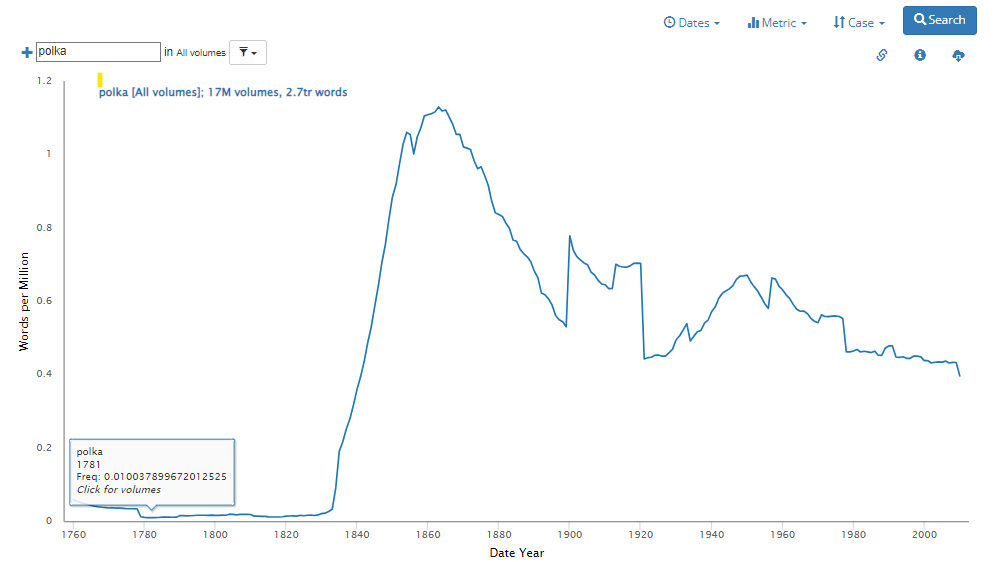

For Workset, you can use an already [created workset](https://htrc.github.io/torchlite-handbook/worksets.html) or [use API calls to create your own.](https://htrc.stoplight.io/docs/ef-api/12faa9205623e-create-workset) We are using the [Dune workset](
https://analytics.dev.htrc.indiana.edu/publicworksets/ca530b50-1f33-4911-88b6-0fbcc70e8259) from the featured worksets. First, we will set the workset id:

In [ ]:
worksetid = "66477e0b2600006a07132b28"; # define the workset

### API Calls

The EF API gives us a lot of options for types of API calls we can make. For this particular visualizations, we are going to use the "GET volumes aggregated by workset id", will give us all the token data for each volume in the workset, aggregated at the volume level rather than the page level.

The advantage to using the aggregated data is that it's much faster at retrieving tokens than other API calls which get data at the page level, so if I have an application or visualization that doesn't need parts of speech, or page level token data, I can use the aggregated data for a more performant visualization.

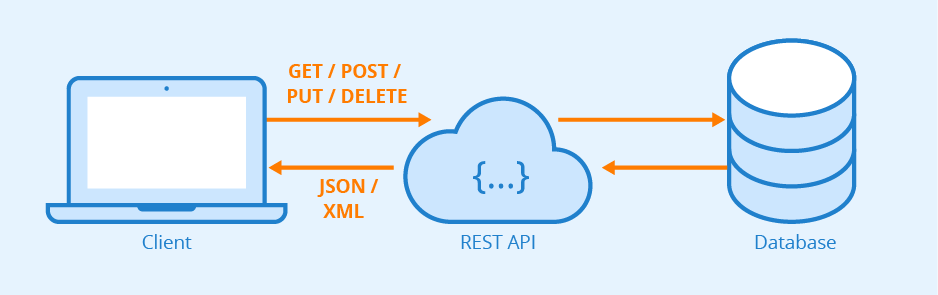

In [ ]:
import requests # importing the requests library which will allow us to use the EF API

url = f"https://data.htrc.illinois.edu/ef-api/worksets/{worksetid}/volumes/aggregated"

try:
    print(f"Sending request to: {url}")  # Debugging: Show the URL being requested
    response = requests.get(url)

    # Debugging: Print the status code to check if the response was successful
    print(f"Status code: {response.status_code}")

    # Check if response is successful
    response.raise_for_status()  # raises an error for bad status codes

    # If no exception, print the response and parse it
    print("Response OK! Parsing data...")
    agg_data = response.json()  # using requests to get aggregated data for our workset
    print(agg_data)  # Check the response content
except requests.RequestException as e:
    # Catch any exceptions and print an error message
    print(f"Error fetching data: {e}")



Sending request to: https://data.htrc.illinois.edu/ef-api/worksets/66477e0b2600006a07132b28/volumes/aggregated
Status code: 200
Response OK! Parsing data...
{'code': 200, 'data': [{'htid': 'mdp.49015003071447', 'metadata': {'schemaVersion': 'https://schemas.hathitrust.org/EF_Schema_MetadataSubSchema_v_3.0', 'id': 'http://hdl.handle.net/2027/mdp.49015003071447', 'type': ['DataFeedItem', 'Book'], 'dateCreated': 20200209, 'title': 'Dune /', 'contributor': {'id': 'http://www.viaf.org/viaf/59083797', 'type': 'http://id.loc.gov/ontologies/bibframe/Person', 'name': 'Herbert, Frank.'}, 'pubDate': 1965, 'publisher': {'id': 'http://catalogdata.library.illinois.edu/lod/entities/ProvisionActivityAgent/ht/Ace%20Books', 'type': 'http://id.loc.gov/ontologies/bibframe/Organization', 'name': 'Ace Books'}, 'pubPlace': {'id': 'http://id.loc.gov/vocabulary/countries/nyu', 'type': 'http://id.loc.gov/ontologies/bibframe/Place', 'name': 'New York (State)'}, 'language': 'eng', 'accessRights': 'ic', 'accessPro

### Search a term across an HTRC workset visualization

As you can see in the data property, there are a number of other properties nested below it. What you're probably most interested in is either **metadata** or **features**. Both of these properties give us different facets of the data we can explore. For example, in the features property, we can view token counts for each volume.

For our visualization, we're interesteed in 3 pieces of information:

1.   The token counts for the body text (not interested in the header or footer tokens).
2.   The title, which will be displayed on the x-axis.
3. The publication date.




#### Step 1: Extract relevant features from the original data

First we create a variable called `processed_data` by iterating through each item in `agg_data["data"]` and extracting specific pieces of information. For each object, it pulls the `"body"` and `"tokenCount"` values from the `"features"` section and the `"title"` and `"pubDate"` values from the `"metadata"` section. It also cleans up the title by removing any occurrence of `" /"` using the `replace` method.

In [ ]:
import plotly.graph_objects as go # import the plotly Python library to create a graph

# Step 1: Extract relevant features from the original data
processed_data = [
    {
        "body": obj["features"]["body"],
        "tokenCount": obj["features"]["tokenCount"],
        "title": obj["metadata"]["title"].replace(" /", ""),
        "pubDate": obj["metadata"]["pubDate"]
    }
    for obj in agg_data["data"]
]

#### Step 2: Count word occurrences and calculate relative frequency

Next we create a function, `count_word_occurrences`, which analyzes how often a specific word appears in the volumes and calculates its relative frequency.The function first converts the input word to lowercase to ensure case-insensitive matching. Then, it counts how many times that word appears in the body text. It also calculates the word's relative frequency per 1,000 tokens by dividing the count by the total token count and multiplying by 1,000. Finally, it creates a new dictionary for each item containing the title, count, relative frequency, and publication date, which we will use in the visualization.

In [ ]:
# Step 2: Count word occurrences and calculate relative frequency
def count_word_occurrences(word, data):
    word = word.lower() # lowercases all the words
    result = []

    for obj in data:
        count = sum(v for k, v in obj["body"].items() if k.lower() == word)
        relative_count = (count / obj["tokenCount"]) * 1000 if obj["tokenCount"] else 0

        result.append({
            "title": obj["title"],
            "count": count,
            "relativeCount": relative_count,
            "pubDate": obj["pubDate"]
        })

    return result

#### Step 3: Prepare data for the chart

This function, `prepare_chart_data`, formats the word frequency data so it’s ready to be used in a chart or graph. It takes word_counts as input—this would be the list returned by the count_word_occurrences function. For each entry in that list, it creates a new dictionary containing three fields: "volume" (which comes from the original title), "count" (which is actually the relative frequency of the word), and "pubDate" (the publication date).

In [ ]:

# Step 3: Prepare data for the chart
def prepare_chart_data(word_counts):
    return [
        {
            "volume": obj["title"],
            "count": obj["relativeCount"],
            "pubDate": obj["pubDate"]
        }
        for obj in word_counts
    ]

#### Step 4: Plot bar chart

This code defines and uses a function called `plot_word_frequency_chart` to create a bar chart that shows how frequently a specific word appears across our workset. The function takes three arguments: `data` (a list of dictionaries prepared for plotting), `search_term` (the word being analyzed), and an optional `order_func` (used to sort the data before plotting). If `order_func` is provided, it sorts the data accordingly—for example, by publication date or frequency.

It then uses **Plotly**, a Python graphing library, to create a bar chart. The x-axis represents the titles of the documents (`"volume"`), and the y-axis shows the relative word frequency (`"count"`), which is the number of times the word appears per 1,000 words.

In [ ]:
# Step 4: Plot bar chart
def plot_word_frequency_chart(data, search_term, order_func=None):
    if order_func:
        data.sort(key=order_func)

    fig = go.Figure(data=[go.Bar(
        x=[d["volume"] for d in data],
        y=[d["count"] for d in data],
        marker_color='steelblue'
    )])

    fig.update_layout(
        title=f"Search Term: {search_term} (words per 1,000)",
        xaxis_title="Volume Title",
        yaxis_title="Relative Frequency",
        xaxis_tickangle=-45,
        template="plotly_white"
    )

    fig.show()

# Run
search_term = "paul"
word_counts = count_word_occurrences(search_term, processed_data)
chart_data = prepare_chart_data(word_counts)
plot_word_frequency_chart(chart_data, search_term)

### Interactive Version of the chart!

In [ ]:
import dash
from dash import dcc, html, Input, Output
import plotly.graph_objects as go
import datetime

# Sample processed data (replace this with your actual `agg_data` processing)
processed_data = [
    {
        "body": obj["features"]["body"],
        "tokenCount": obj["features"]["tokenCount"],
        "title": obj["metadata"]["title"].replace(" /", ""),
        "pubDate": obj["metadata"]["pubDate"]
    }
    for obj in agg_data["data"]
]


# Count word occurrences and calculate relative frequency
def count_word_occurrences(word, data):
    word = word.lower()
    result = []

    for obj in data:
        count = sum(v for k, v in obj["body"].items() if k.lower() == word)
        relative_count = (count / obj["tokenCount"]) * 1000 if obj["tokenCount"] else 0

        result.append({
            "title": obj["title"],
            "count": count,
            "relativeCount": relative_count,
            "pubDate": obj["pubDate"]
        })

    return result

# Prepare chart data
def prepare_chart_data(word_counts, sort_by):
    if sort_by == "frequency":
        word_counts.sort(key=lambda x: x["relativeCount"], reverse=True)
    elif sort_by == "date":
        word_counts.sort(key=lambda x: x["pubDate"])  # <- Fix here
    return word_counts

# Dash App Setup
app = dash.Dash(__name__)

app.layout = html.Div([
    html.H2("Word Frequency Chart (per 1,000 words)"),
    dcc.Input(id='search-term', type='text', value='time', placeholder='Enter word...'),
    dcc.Dropdown(
        id='sort-method',
        options=[
            {'label': 'Frequency', 'value': 'frequency'},
            {'label': 'Publication Date', 'value': 'date'}
        ],
        value='frequency',
        clearable=False
    ),
    dcc.Graph(id='bar-chart')
])

@app.callback(
    Output('bar-chart', 'figure'),
    Input('search-term', 'value'),
    Input('sort-method', 'value')
)
def update_chart(search_term, sort_method):
    word_counts = count_word_occurrences(search_term, processed_data)
    chart_data = prepare_chart_data(word_counts, sort_method)

    fig = go.Figure(data=[go.Bar(
        x=[d["title"] for d in chart_data],
        y=[d["relativeCount"] for d in chart_data],
        marker_color='steelblue'
    )])

    fig.update_layout(
        title=f"Search Term: {search_term} (words per 1,000)",
        xaxis_title="Volume Title",
        yaxis_title="Relative Frequency",
        xaxis_tickangle=-45,
        template="plotly_white"
    )

    return fig

if __name__ == '__main__':
    app.run(debug=True)


<IPython.core.display.Javascript object>